## 3.2 Lingkungan Pengembangan
Library Python yang digunakan: Pandas, NumPy, Matplotlib, Seaborn, dan Scikit-learn.

In [ ]:
# Pengolahan data (Pandas & NumPy)
import pandas as pd
import numpy as np
# Visualisasi (Matplotlib & Seaborn)
import matplotlib.pyplot as plt
import seaborn as sns
# Scikit-learn: split data, model Decision Tree, dan metrik evaluasi
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
# Akses Google Drive (Google Colab)
from google.colab import drive

## 3.3 Tahapan Praktikum
### Menyiapkan struktur folder & lingkungan pengembangan

In [ ]:
# [3.3] Menyiapkan lingkungan: mount Google Drive agar dataset di folder pertemuan5/data bisa diakses
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3.1 Dataset yang Digunakan & 4.1 Hasil Loading Dataset
Dataset Iris, target klasifikasi = kolom Species.

In [ ]:
# [3.3 & 4.1] Loading dataset Iris dari file CSV, lalu tampilkan 5 data teratas dengan head()
df = pd.read_csv('/content/drive/MyDrive/Kampus/semester7/machine learning/pertemuan5/data/dataset_iris.csv')
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
# [3.3 & 4.1] Melihat struktur dataset: jumlah data, nama kolom, dan tipe data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


## 4.2 Hasil Preprocessing Data

In [ ]:
# Cek missing value
df.isnull().sum()

,0
Id,0
SepalLengthCm,0
SepalWidthCm,0
PetalLengthCm,0
PetalWidthCm,0
Species,0


In [ ]:
# Cek duplicate (kolom Id tidak ikut diperiksa karena unik)
print("Duplikat sebelum:", df.drop(columns='Id').duplicated().sum())
df = df.loc[~df.drop(columns='Id').duplicated()].reset_index(drop=True)
print("Duplikat sesudah :", df.drop(columns='Id').duplicated().sum())
print("Jumlah data      :", len(df))

Duplikat sebelum: 3
Duplikat sesudah : 0
Jumlah data      : 147


In [ ]:
# [4.2] Preprocessing: rapikan nama kolom (huruf kecil, tanpa 'Cm') dan hapus kolom Id
df = df.rename(columns={
    'SepalLengthCm':'sepal_length',
    'SepalWidthCm':'sepal_width',
    'PetalLengthCm':'petal_length',
    'PetalWidthCm':'petal_width',
    'Species':'species'
})
df = df.drop(columns='Id')   # Id hanya penomoran, bukan fitur
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 147 entries, 0 to 146
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  147 non-null    float64
 1   sepal_width   147 non-null    float64
 2   petal_length  147 non-null    float64
 3   petal_width   147 non-null    float64
 4   species       147 non-null    object 
dtypes: float64(4), object(1)
memory usage: 5.9+ KB


## Eksplorasi Data (Visualisasi)

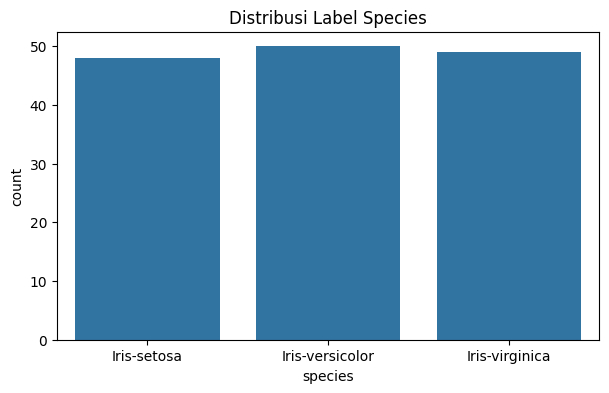

In [ ]:
# [3.3] Eksplorasi: melihat distribusi jumlah data tiap species (apakah seimbang/tidak)
plt.figure(figsize=(7,4))
sns.countplot(x=df['species'])
plt.title('Distribusi Label Species')
plt.show()

In [ ]:
# [4.2] Encoding target: ubah label teks species menjadi angka agar bisa diproses model
# mapping label -> kode untuk target
species_cat = df['species'].astype('category')
species_classes = list(species_cat.cat.categories)
df['species'] = species_cat.cat.codes
print(dict(enumerate(species_classes)))
df.head()

{0: 'Iris-setosa', 1: 'Iris-versicolor', 2: 'Iris-virginica'}


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## 3.3 Menentukan Fitur (X) dan Target (y)

In [ ]:
# [3.3] X = fitur (4 ukuran bunga), y = target (species)
feature_cols = ['sepal_length','sepal_width','petal_length','petal_width']
X = df[feature_cols]
y = df['species']

## 4.3 Hasil Pembagian Dataset (80:20)

In [ ]:
# [3.3 & 4.3] Bagi data: 80% training & 20% testing
# stratify=y -> proporsi tiap species tetap sama di training & testing
# random_state=42 -> hasil pembagian selalu sama saat dijalankan ulang
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Data training:", len(X_train))
print("Data testing :", len(X_test))

Data training: 117
Data testing : 30


In [ ]:
# Rincian pembagian data (poin 2)
n_total = len(X)
print(f"Data training : {len(X_train)} ({len(X_train)/n_total:.0%})")
print(f"Data testing  : {len(X_test)} ({len(X_test)/n_total:.0%})")
print("\nJumlah tiap species (training):")
print(y_train.map(dict(enumerate(species_classes))).value_counts())
print("\nJumlah tiap species (testing):")
print(y_test.map(dict(enumerate(species_classes))).value_counts())

Data training : 117 (80%)
Data testing  : 30 (20%)

Jumlah tiap species (training):
species
Iris-versicolor    40
Iris-virginica     39
Iris-setosa        38
Name: count, dtype: int64

Jumlah tiap species (testing):
species
Iris-versicolor    10
Iris-virginica     10
Iris-setosa        10
Name: count, dtype: int64


## 4.4 Hasil Pemodelan Decision Tree

In [ ]:
# [3.3 & 4.4] Membangun & melatih model Decision Tree
# criterion='gini' -> ukuran impurity untuk menentukan percabangan
# max_depth=4      -> batasi kedalaman pohon agar tidak overfitting
# random_state=42  -> hasil konsisten
# .fit()           -> proses training memakai data training
dt = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
dt.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

## 4.5 Hasil Evaluasi Model

In [ ]:
# [3.4 & 4.5] Prediksi data testing + evaluasi: Accuracy, Confusion Matrix, Classification Report
# (Precision, Recall, F1-Score). Akurasi training dibandingkan testing untuk cek overfitting
y_pred = dt.predict(X_test)

print("Akurasi Training:", round(accuracy_score(y_train, dt.predict(X_train))*100, 2), "%")
print("Akurasi Testing :", round(accuracy_score(y_test, y_pred)*100, 2), "%")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=species_classes))

Akurasi Training: 99.15 %
Akurasi Testing : 93.33 %

Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification Report:
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



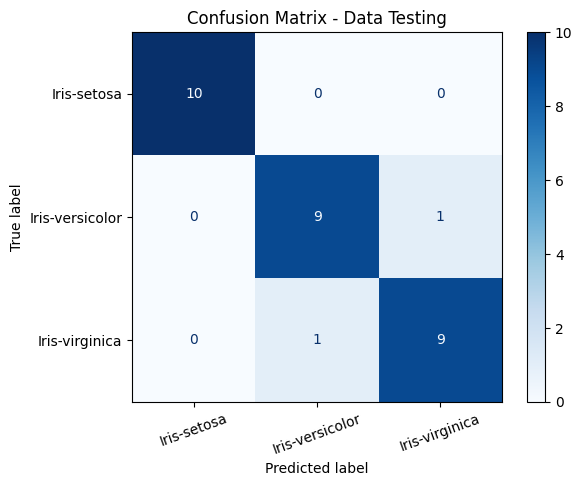

In [ ]:
# [4.5] Visualisasi Confusion Matrix pada data testing
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=species_classes, cmap='Blues', xticks_rotation=20)
plt.title('Confusion Matrix - Data Testing')
plt.show()

## 4.6 Hasil Pengujian Data Testing

In [ ]:
# Hasil pengujian per data testing
hasil = X_test.copy()
hasil['aktual'] = [species_classes[i] for i in y_test]
hasil['prediksi'] = [species_classes[i] for i in y_pred]
hasil['benar'] = hasil['aktual'] == hasil['prediksi']
hasil

,sepal_length,sepal_width,petal_length,petal_width,aktual,prediksi,benar
61,6.1,2.9,4.7,1.4,Iris-versicolor,Iris-versicolor,True
82,5.4,3.0,4.5,1.5,Iris-versicolor,Iris-versicolor,True
139,6.9,3.1,5.1,2.3,Iris-virginica,Iris-virginica,True
42,5.1,3.8,1.9,0.4,Iris-setosa,Iris-setosa,True
144,6.5,3.0,5.2,2.0,Iris-virginica,Iris-virginica,True
75,6.7,3.0,5.0,1.7,Iris-versicolor,Iris-virginica,False
54,6.3,3.3,4.7,1.6,Iris-versicolor,Iris-versicolor,True
38,5.0,3.5,1.3,0.3,Iris-setosa,Iris-setosa,True
136,6.0,3.0,4.8,1.8,Iris-virginica,Iris-virginica,True
125,6.1,3.0,4.9,1.8,Iris-virginica,Iris-virginica,True


In [ ]:
# [4.6] Hitung jumlah prediksi benar & salah, tampilkan data yang salah diprediksi
jml_benar = int(hasil['benar'].sum())
print(f"Prediksi benar : {jml_benar} dari {len(hasil)} data testing")
print(f"Prediksi salah : {len(hasil)-jml_benar} dari {len(hasil)} data testing")
print("\nData yang salah diprediksi:")
display(hasil[~hasil['benar']])

Prediksi benar : 28 dari 30 data testing
Prediksi salah : 2 dari 30 data testing

Data yang salah diprediksi:


,sepal_length,sepal_width,petal_length,petal_width,aktual,prediksi,benar
75,6.7,3.0,5.0,1.7,Iris-versicolor,Iris-virginica,False
132,6.1,2.6,5.6,1.4,Iris-virginica,Iris-versicolor,False


## 4.7 Visualisasi Model

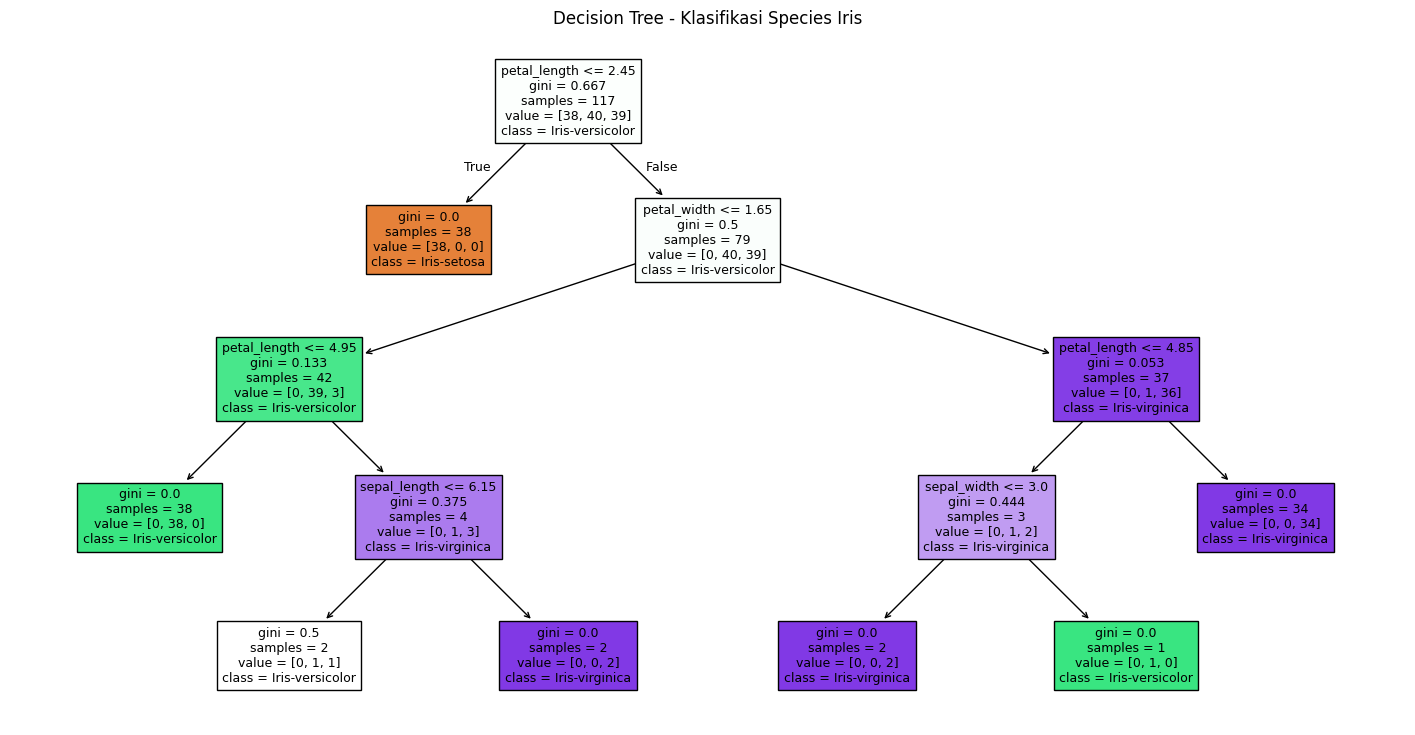

In [ ]:
# [4.7] Visualisasi pohon keputusan: node, cabang (kondisi fitur), dan leaf (hasil kelas)
plt.figure(figsize=(18,9))
plot_tree(dt, feature_names=feature_cols, class_names=species_classes, filled=True, fontsize=9)
plt.title("Decision Tree - Klasifikasi Species Iris")
plt.show()